# Phân tích khám phá dữ liệu (EDA)

Notebook này mô tả bộ dữ liệu tin tuyển dụng **trước khi** tin vào kết quả RQ1–RQ4: dữ liệu thiếu gì, văn bản dài ngắn ra sao, viết bằng tiếng gì, đăng khi nào, công ty nào đăng nhiều, kỹ năng phân bố thế nào, và tin được giữ khác tin bị loại ở đâu.

**Đầu vào:** `data/raw/jobs_raw.jsonl` (gộp các đợt thu bằng `scripts/combine_raw.py`) và `data/processed/jobs_clean.parquet` (đầu ra của bước làm sạch trong pipeline). Code nằm ở `src/analysis/eda.py`; chạy không cần notebook bằng `python -m src.analysis.eda`. Mọi bảng ở đây là số tổng hợp, không in văn bản tin tuyển dụng.

In [1]:
import os, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.analysis import eda

RAW = os.environ.get("EDA_RAW", ROOT / "data/raw/jobs_raw.jsonl")
CLEAN = os.environ.get("EDA_CLEAN", ROOT / "data/processed/jobs_clean.parquet")
TAXONOMY = ROOT / "taxonomy/skills_taxonomy.csv"
OUT = Path(os.environ.get("EDA_OUT", ROOT / "reports/eda"))

df, tables = eda.run(RAW, CLEAN, TAXONOMY, OUT, log=lambda *_: None)
show = lambda name, width=760: display(Image(filename=str(OUT / name), width=width))
tables["eda_summary"]

,metric,value
0,Tin thô sau gộp,504
1,Tin hợp lệ,402
2,Công ty khác nhau (tin hợp lệ),239
3,Tỷ trọng 10 công ty đăng nhiều nhất,0.1816
4,Công ty chỉ đăng 1 tin,166
5,"Độ dài văn bản trung vị (ký tự, tin hợp lệ)",2567
6,Số kỹ năng trung bình (tin hợp lệ),10.6
7,Tỷ lệ kỹ năng lõi Data/AI trung vị (tin hợp lệ),0.5
8,Ngày đăng sớm nhất,2026-08-11
9,Ngày đăng muộn nhất,2026-11-03


## 1. Quy mô và trạng thái

Mỗi tin thuộc một trong ba trạng thái: hợp lệ, bị loại vì ngoài phạm vi Data/AI, hoặc bị loại vì là bản trùng. Bảng dưới tách theo đợt thu.

In [2]:
tables["eda_status_by_round"]

status,round,Bị loại (ngoài phạm vi),Bị loại (trùng),Hợp lệ
0,Pilot 30/09,38,5,209
1,Đợt 03/11,34,25,193


Đợt 03/11 có nhiều tin trùng hơn (25 so với 5) vì một số vị trí đăng lại với đường dẫn mới giữa hai đợt.

## 2. Dữ liệu thiếu

Trang ITviec ghi "Not Available" cho nhiều địa điểm; chuỗi này được tính là thiếu.

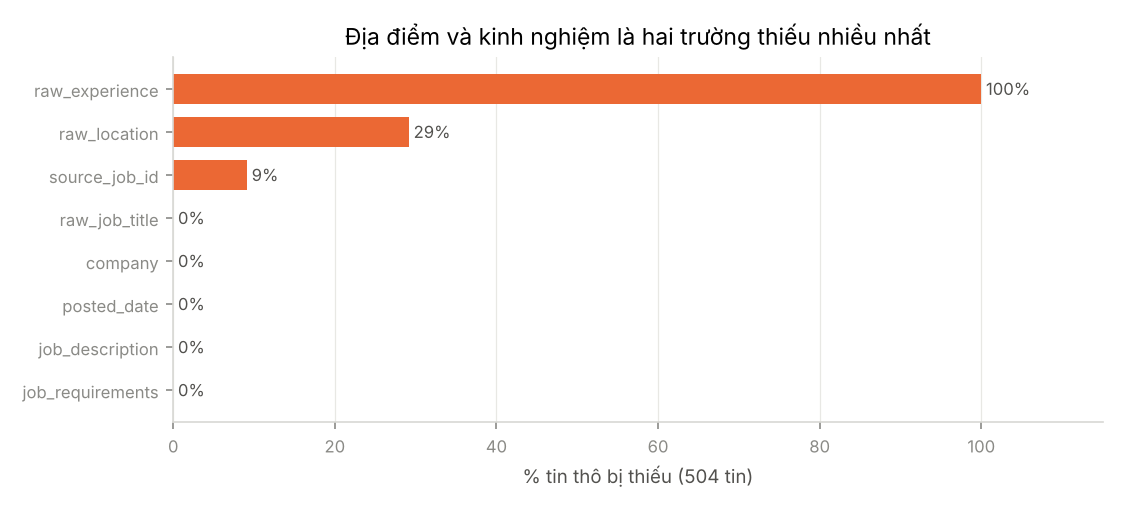

,field,missing,share
0,source_job_id,46,0.0913
1,raw_job_title,0,0.0000
2,company,0,0.0000
3,raw_location,147,0.2917
4,posted_date,0,0.0000
5,raw_experience,504,1.0000
6,job_description,0,0.0000
7,job_requirements,0,0.0000


In [3]:
show("eda_missing.png", 640)
tables["eda_missing_by_field"]

Kinh nghiệm thiếu 100% vì crawler chưa lấy được trường này; địa điểm thiếu 29%. Cả hai không ảnh hưởng RQ2–RQ4 (chỉ dùng chức danh và văn bản), nhưng làm phần mô tả địa điểm ở RQ1 kém tin cậy.

## 3. Văn bản: độ dài và ngôn ngữ

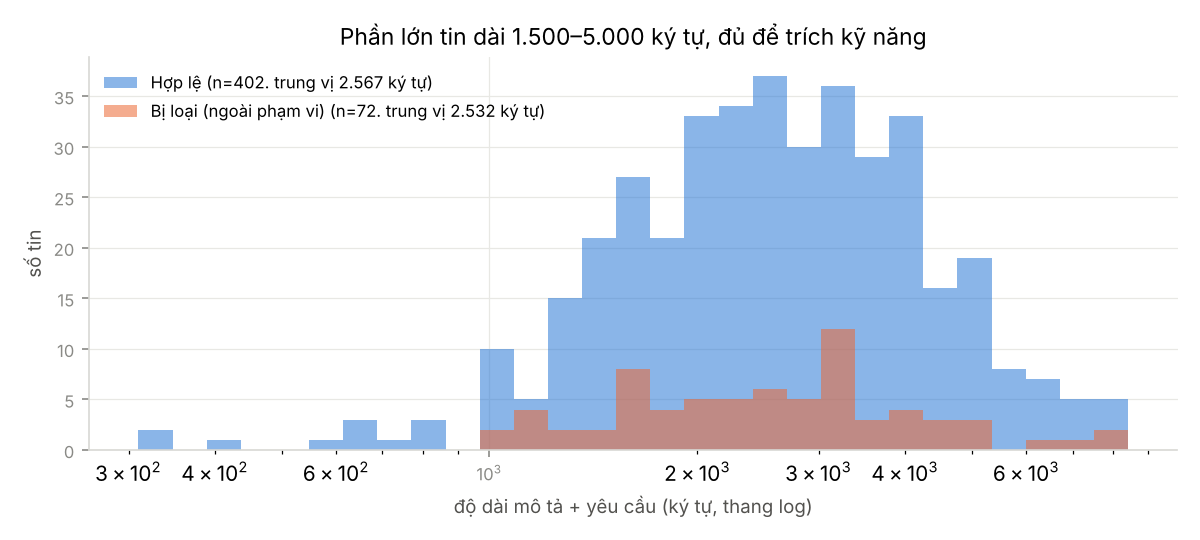

In [4]:
show("eda_text_length.png")

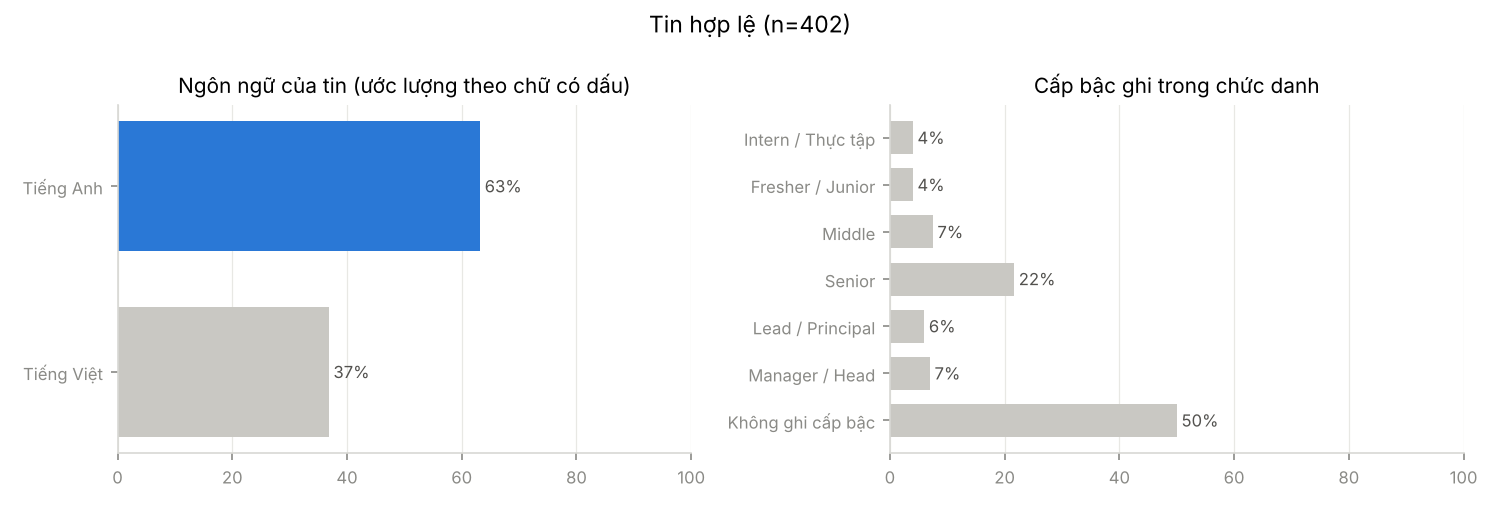

,status,language,n
0,Bị loại (ngoài phạm vi),Tiếng Anh,47
1,Bị loại (ngoài phạm vi),Tiếng Việt,25
2,Bị loại (trùng),Tiếng Anh,17
3,Bị loại (trùng),Tiếng Việt,13
4,Hợp lệ,Tiếng Anh,254
5,Hợp lệ,Tiếng Việt,148


In [5]:
show("eda_language_seniority.png", 820)
tables["eda_language"]

Khoảng 63% tin hợp lệ viết bằng tiếng Anh, 37% bằng tiếng Việt (ước lượng theo tỷ lệ chữ có dấu). Bộ trích xuất và taxonomy vì vậy phải bắt được cả thuật ngữ tiếng Việt. Một nửa chức danh không ghi cấp bậc; Senior là cấp bậc hay gặp nhất (22%).

## 4. Thời gian đăng

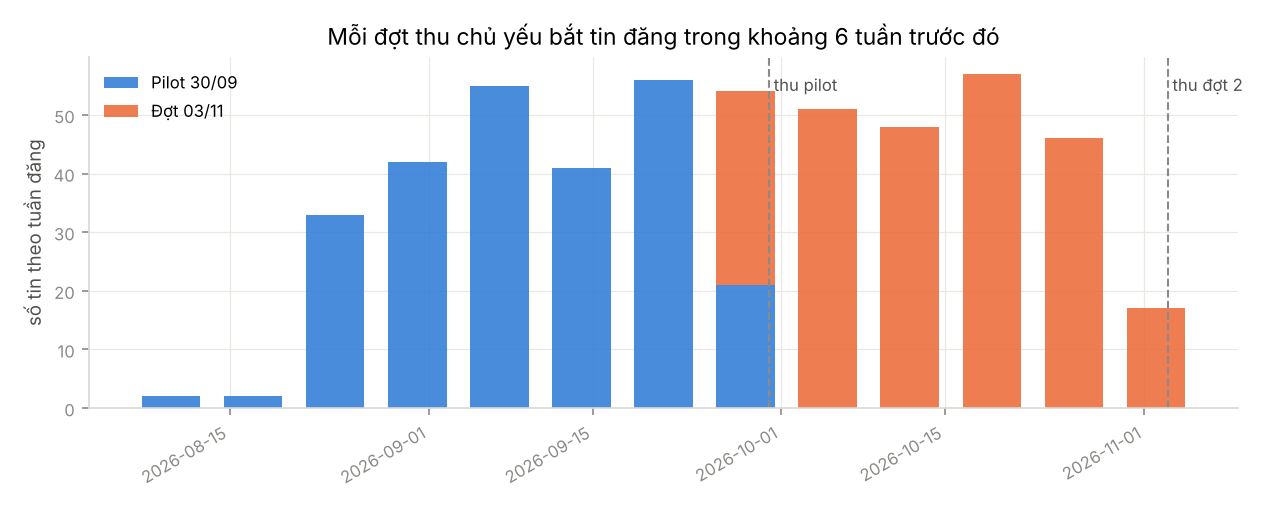

In [6]:
show("eda_posted_dates.png")

Mỗi đợt thu chủ yếu bắt các tin đăng trong khoảng 6 tuần trước đó, và hai đợt gần như không chồng lên nhau. Thu thêm các đợt trước ngày chốt 23/11 sẽ tiếp tục thêm tin mới.

## 5. Công ty

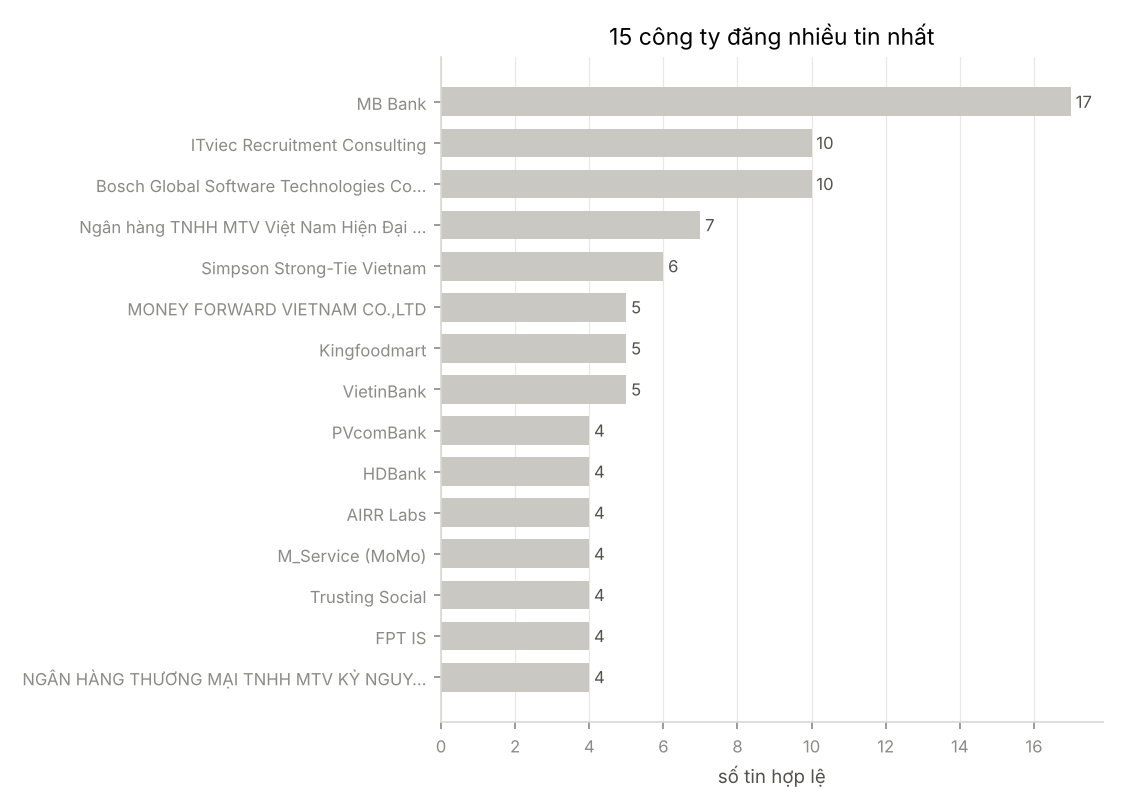

,company,count
0,MB Bank,17
1,ITviec Recruitment Consulting,10
2,Bosch Global Software Technologies Company Lim...,10
3,Ngân hàng TNHH MTV Việt Nam Hiện Đại (MBV),7
4,Simpson Strong-Tie Vietnam,6
5,"MONEY FORWARD VIETNAM CO.,LTD",5
6,Kingfoodmart,5
7,VietinBank,5
8,PVcomBank,4
9,HDBank,4


In [7]:
show("eda_top_companies.png", 640)
tables["eda_top_companies"].head(10)

Dữ liệu không bị một công ty chi phối: 402 tin đến từ 239 công ty, 10 công ty lớn nhất chiếm 18%. Ngân hàng chiếm nhiều vị trí trong top 15. "ITviec Recruitment Consulting" là đơn vị tuyển dụng trung gian đăng thay cho nhiều công ty khác.

## 6. Kỹ năng

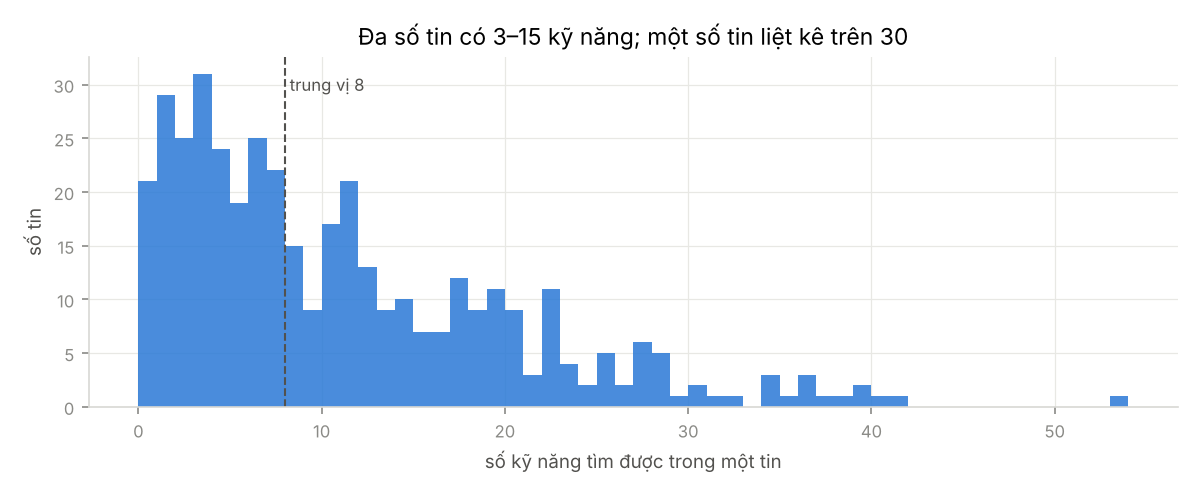

In [8]:
show("eda_skills_per_posting.png")

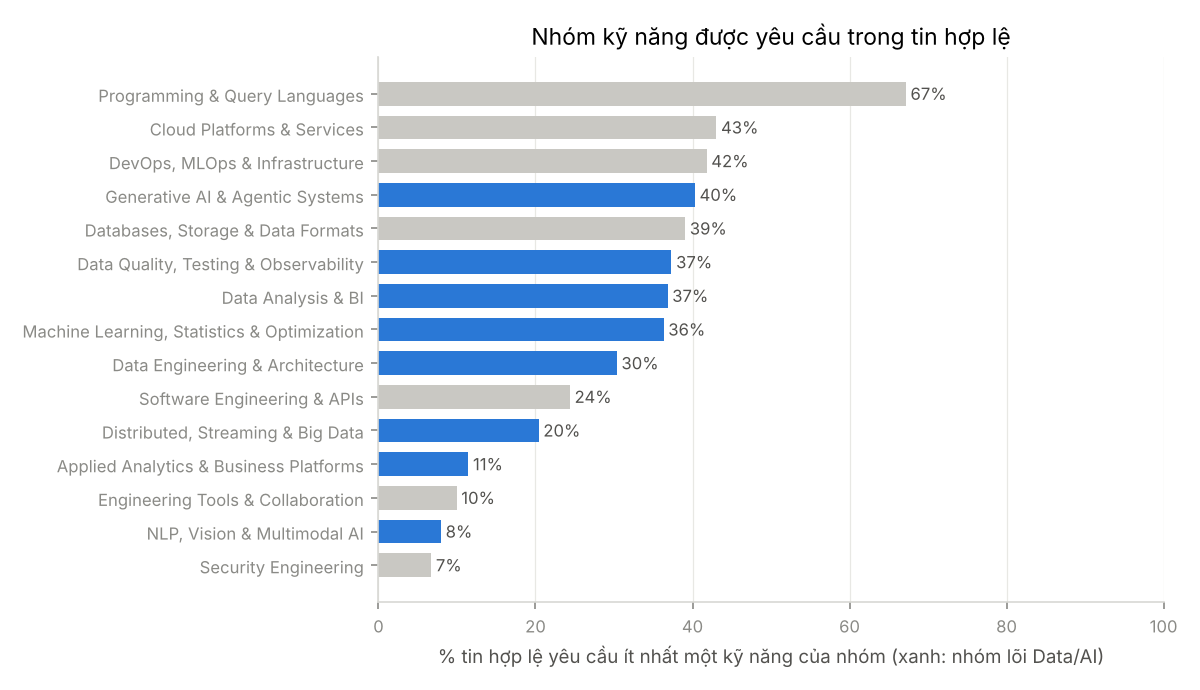

In [9]:
show("eda_skill_groups.png")

Ngôn ngữ lập trình và truy vấn (Python, SQL…) có mặt ở 67% tin. Các nhóm hạ tầng (Cloud, DevOps) đứng ngay sau, cao hơn các nhóm lõi Data/AI như Phân tích & BI hay Kỹ nghệ dữ liệu. Đây là dấu hiệu đầu tiên của việc tin IT chung lọt vào.

## 7. Kiểm tra bộ lọc liên quan

Chạy bộ trích xuất trên **mọi** tin (kể cả tin bị loại) rồi tính, với mỗi tin, tỷ lệ kỹ năng thuộc các nhóm lõi Data/AI. Tin được chia theo nhóm chức danh bằng một phân loại thô (chỉ để mô tả).

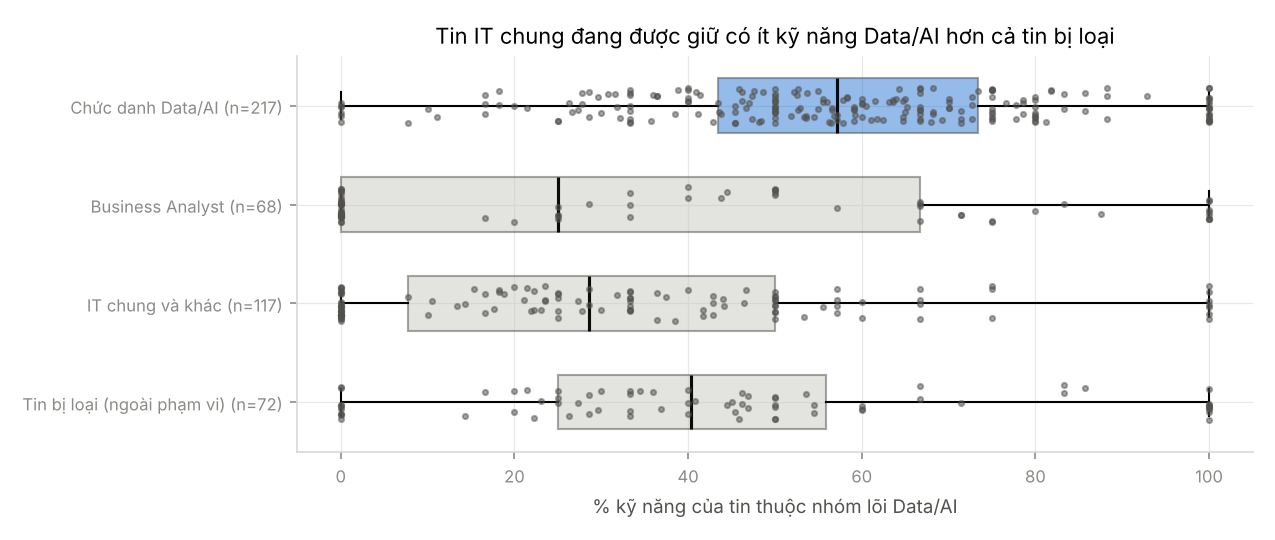

,status,title_group,n,median_text_len,mean_skills,median_core_share
0,Bị loại (ngoài phạm vi),Business Analyst,2,2349.5,3.500,0.250
1,Bị loại (ngoài phạm vi),Chức danh Data/AI,23,3366.0,14.913,0.368
2,Bị loại (ngoài phạm vi),IT chung và khác,47,2440.0,8.957,0.450
3,Bị loại (trùng),Business Analyst,4,1895.0,3.000,0.083
4,Bị loại (trùng),Chức danh Data/AI,22,2392.0,18.500,0.559
5,Bị loại (trùng),IT chung và khác,4,4112.5,11.000,0.150
6,Hợp lệ,Business Analyst,68,2221.0,3.147,0.250
7,Hợp lệ,Chức danh Data/AI,217,2597.0,14.539,0.571
8,Hợp lệ,IT chung và khác,117,2709.0,7.632,0.286


In [10]:
show("eda_filter_check.png")
tables["eda_title_group_profile"]

Tin hợp lệ có chức danh Data/AI có trung vị 57% kỹ năng lõi Data/AI. Nhưng 117 tin IT chung đang được giữ chỉ có trung vị 29%, **thấp hơn cả tin bị loại** (40%). Ngược lại, một số tin bị loại có chức danh như "AI Software Engineer" hay "Principal Software Engineer (LLM Agents)", có thể thuộc phạm vi. Bộ lọc vì vậy sai theo cả hai chiều. Tỷ lệ kỹ năng lõi Data/AI là một tín hiệu có thể dùng để siết bộ lọc, kết hợp với chức danh.

## 8. Tóm tắt

| Điều EDA cho thấy | Hệ quả |
|---|---|
| Kinh nghiệm thiếu 100%, địa điểm thiếu 29% | Sửa crawler; ghi hạn chế cho phần địa điểm ở RQ1 |
| 63% tin tiếng Anh, 37% tiếng Việt | Taxonomy phải giữ alias tiếng Việt |
| Hai đợt thu gần như không chồng nhau | Thu thêm đợt trước 23/11 để tăng số tin |
| 239 công ty, top 10 chiếm 18% | Không có công ty chi phối dữ liệu |
| Nhóm Cloud/DevOps cao hơn nhóm lõi Data/AI | Dấu hiệu tin IT chung lọt vào |
| Tin IT chung được giữ có ít kỹ năng Data/AI hơn tin bị loại | Phải siết bộ lọc liên quan trước khi chốt dữ liệu |